# Procesos gaussianos aplicados a las exportaciones de yerba mate argentina entre 2002 y 2026
### por Ignacio Lopez Parra

**Pregunta central.** ¿Las exportaciones mensuales de yerba mate argentina (ene-2002 a sep-2026) tienen una estacionalidad anual identificable, o su variación mensual es sobre todo ruido alrededor de una tendencia lenta?

**Objetivos.**
1. **Estructura:** comparar kernels que representan hipótesis distintas sobre la dependencia temporal (solo ruido; dependencia de corto plazo; tendencia sin ciclo; tendencia más ciclo anual).
2. **Magnitud:** estimar qué parte de la varianza corresponde a la tendencia, al ciclo anual y al ruido.
3. **Utilidad:** evaluar si esa estructura mejora el pronóstico frente a referencias simples y si las bandas predictivas están calibradas.

**Datos.** Exportaciones mensuales de yerba mate en kg (INDEC, Sistema de Consulta de Comercio Exterior de Bienes), archivo `yerba_mate_export_2002_2026.csv` (columnas `fecha`, `export_kg`), 297 observaciones.

**Método.** Regresión con procesos gaussianos (`scikit-learn`). La media histórica, los pronósticos naive (último valor observado) y naive estacional (mismo mes del año anterior) y un ARIMA(1,0,0) se usan solo como referencia para evaluar si la estructura estimada mejora el pronóstico.

# 0. Importación de librerías

In [1]:
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats
import sklearn
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, Matern, ConstantKernel, WhiteKernel, ExpSineSquared
import statsmodels
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

warnings.filterwarnings('ignore')
SEMILLA = 42

print(f"Python: {sys.version.split()[0]}")
print(f"scikit-learn: {sklearn.__version__} | statsmodels: {statsmodels.__version__}")
print(f"numpy: {np.__version__} | pandas: {pd.__version__} | scipy: {scipy.__version__} | matplotlib: {matplotlib.__version__}")

Python: 3.13.16
scikit-learn: 1.6.1 | statsmodels: 0.15.0
numpy: 2.4.6 | pandas: 2.2.3 | scipy: 1.16.3 | matplotlib: 3.10.0


## 1. Datos y exploración

La respuesta es $b_t=\ln(\text{kg}_t)$. El logaritmo natural estabiliza la varianza (las exportaciones salen por embarques y tienen picos multiplicativos) y permite leer los efectos como variaciones porcentuales aproximadas. El tiempo $t$ se expresa en años decimales, de modo que el período anual vale 1.

### Carga de los datos y totales anuales

In [2]:
# Carga de datos
datos = pd.read_csv('../datos/yerba_mate_export_2002_2026.csv', parse_dates=['fecha'], index_col='fecha').asfreq('MS')
kg = datos['export_kg']
b = np.log(kg.values)
t = (datos.index.year + (datos.index.month - 1) / 12).values.astype(float)
n = len(b)
print(f'Observaciones: {n}  ({datos.index.min():%Y-%m} a {datos.index.max():%Y-%m}); faltantes: {kg.isna().sum()}')
print(f'Media: {kg.mean() / 1e6:.2f} M kg por mes')

# Tabla de datos anualizados
anual = (kg.groupby(kg.index.year).agg(['sum', 'count']))
anual['sum'] = (anual['sum'] / 1e6).round(1)
anual.columns = ['Total (M kg)', 'Meses']
pd.set_option('display.max_columns', None)
display(anual.T)

Observaciones: 297  (2002-01 a 2026-09); faltantes: 0
Media: 2.88 M kg por mes


fecha,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
Total (M kg),24.9,29.3,27.2,24.6,25.9,28.4,32.2,34.2,33.6,33.4,33.4,32.7,32.1,35.6,27.6,30.8,41.0,39.9,41.8,32.5,40.2,36.1,42.0,55.0,40.5
Meses,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,9.0


### Serie mensual y media móvil de 12 meses

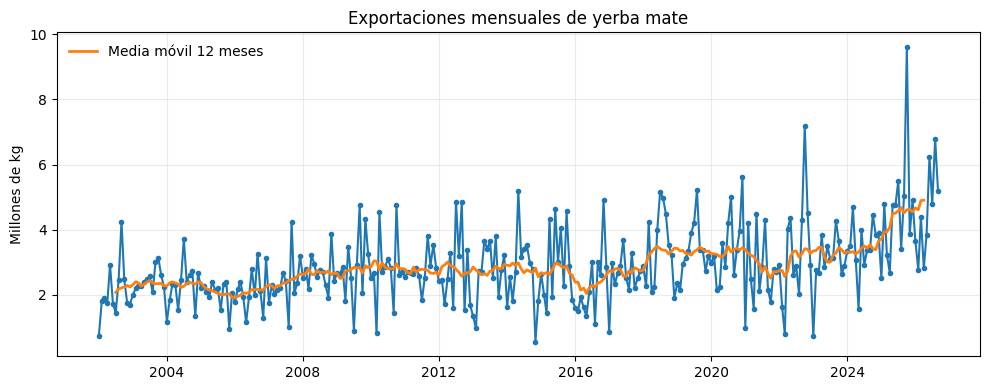

In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(datos.index, kg / 1e6, 'o-', ms=3)
ax.plot(datos.index, kg.rolling(12, center=True).mean() / 1e6, lw=2, label='Media móvil 12 meses')
ax.set(title='Exportaciones mensuales de yerba mate', ylabel='Millones de kg')
ax.legend(frameon=False)
ax.grid(alpha=.25)

plt.tight_layout()
plt.show()

### Distribución por mes calendario
Diagrama de caja de ln(kg) para cada mes y desvío medio de cada mes respecto de la media general.

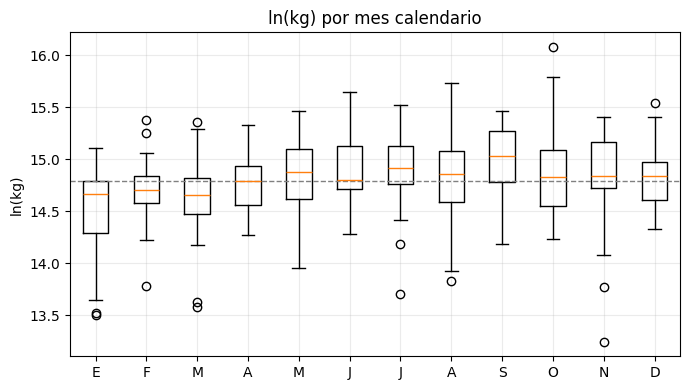

Desvío medio de cada mes respecto de la media (ln):
          1    2     3     4     5     6     7     8     9     10    11    12
efecto -0.32 -0.1 -0.16 -0.04  0.04  0.09  0.12  0.06  0.22  0.11 -0.02  0.02


In [4]:
por_mes = [b[datos.index.month == m] for m in range(1, 13)]

fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot(por_mes)
ax.set_xticks(range(1, 13), list('EFMAMJJASOND'))
ax.axhline(b.mean(), color='gray', ls='--', lw=1)
ax.set(title='ln(kg) por mes calendario', ylabel='ln(kg)')
ax.grid(alpha=.25)

plt.tight_layout()
plt.show()

efecto_mes = pd.Series([x.mean() - b.mean() for x in por_mes], index=range(1, 13))
print('Desvío medio de cada mes respecto de la media (ln):')
print(efecto_mes.round(2).to_frame('efecto').T.to_string())

### Estacionariedad

Se aplica el contraste de Dickey-Fuller aumentado (ADF), con constante y con constante y tendencia. Si el ADF no rechaza la raíz unitaria con solo constante pero sí al incluir la tendencia, la serie es estacionaria alrededor de una tendencia, lo que justifica incluir en el GP una componente suave de largo plazo en lugar de diferenciar.

In [5]:
filas = []
for reg in ('c', 'ct'):
    est, p, *_ = adfuller(b, regression=reg, autolag='AIC')
    filas.append((f'ADF ({reg})', est, p))
display(pd.DataFrame(filas, columns=['Contraste', 'Estadístico', 'p-valor']).round(4))

,Contraste,Estadístico,p-valor
0,ADF (c),-0.9201,0.7813
1,ADF (ct),-15.9857,0.0000


## 2. Especificación del proceso gaussiano

Se modela $b(t)=m+f(t)+\varepsilon_t$, con $f\sim\mathcal{GP}(0,k)$ y $\varepsilon_t\sim N(0,\sigma_n^2)$.
La respuesta se estandariza con su media y su desvío antes de cada ajuste (normalize_y=False), y los pronósticos se vuelven a la escala original.

**Kernels candidatos:** solo ruido, exponencial (Matern con $\nu=1/2$, equivalente a un AR(1)), RBF, Matérn 3/2 y Periódico + Matérn. Todos, salvo el de solo ruido, suman un WhiteKernel.

**Cotas:** período fijo en 1 año; escalas $\ell$ en $[1/12, 10]$ años; escala del periódico en $[0{,}05, 10]$; amplitudes en $[10^{-3}, 10^2]$; ruido en $[10^{-5}, 2]$.

Cada ajuste usa 10 reinicios del optimizador y los modelos se comparan con $\text{AIC}=2k-2\log ML$.

In [6]:
t0 = t[0]
X = (t - t0).reshape(-1, 1)

def estandarizar(bb):
    nivel, escala = bb.mean(), bb.std()
    return (bb - nivel) / escala, nivel, escala

L_MIN = 1 / 12  # un mes, en años

def kernels_candidatos(l_min=L_MIN, l_per_min=0.05, periodo_libre=False):
    amplitud = lambda: ConstantKernel(1., (1e-3, 1e2))
    ruido = lambda: WhiteKernel(.1, (1e-5, 2.))
    cota_periodo = (.95, 1.05) if periodo_libre else 'fixed'
    periodico = lambda: amplitud() * ExpSineSquared(
        length_scale=1., periodicity=1.,
        length_scale_bounds=(l_per_min, 10.), periodicity_bounds=cota_periodo)
    return {
        'Solo ruido': WhiteKernel(1., (1e-5, 10.)),
        'Exponencial': amplitud() * Matern(1., (l_min, 10.), nu=0.5) + ruido(),
        'RBF': amplitud() * RBF(1., (l_min, 10.)) + ruido(),
        'Matérn 3/2': amplitud() * Matern(1., (l_min, 10.), nu=1.5) + ruido(),
        'Periódico + Matérn': periodico() + amplitud() * Matern(1., (l_min, 10.), nu=1.5) + ruido(),
    }

def ajustar(kernel, XX, yy, reinicios=10, semilla=SEMILLA):
    gp = GaussianProcessRegressor(kernel=kernel, alpha=1e-8, normalize_y=False,
                                  n_restarts_optimizer=reinicios, random_state=semilla)
    return gp.fit(XX, yy)

y, nivel, escala = estandarizar(b)
# Media y desvío de ln(kg) en la serie completa, usados para estandarizar la respuesta:
print(f'Media de ln(kg) = {nivel:.4f}; desvío = {escala:.4f}')

Media de ln(kg) = 14.7929; desvío = 0.4126


## 3. Comparación de kernels (Objetivo 1)

In [7]:
### Ajuste de los cinco kernels y tabla de AIC
modelos, filas = {}, []
for nombre, kernel in kernels_candidatos().items():
    gp = ajustar(kernel, X, y)
    logML = gp.log_marginal_likelihood_value_
    k = gp.kernel_.n_dims
    modelos[nombre] = gp
    filas.append((nombre, logML, k, 2 * k - 2 * logML))
    print(f'{nombre:20s} {gp.kernel_}')

tabla_kernels = pd.DataFrame(filas, columns=['Modelo', 'logML', 'k', 'AIC']).set_index('Modelo')
tabla_kernels['ΔAIC'] = tabla_kernels['AIC'] - tabla_kernels['AIC'].min()
display(tabla_kernels.sort_values('AIC').round(2))

Solo ruido           WhiteKernel(noise_level=1)
Exponencial          0.583**2 * Matern(length_scale=10, nu=0.5) + WhiteKernel(noise_level=0.798)
RBF                  0.516**2 * RBF(length_scale=2.21) + WhiteKernel(noise_level=0.803)
Matérn 3/2           0.569**2 * Matern(length_scale=4.29, nu=1.5) + WhiteKernel(noise_level=0.805)
Periódico + Matérn   0.4**2 * ExpSineSquared(length_scale=1.54, periodicity=1) + 0.611**2 * Matern(length_scale=4.65, nu=1.5) + WhiteKernel(noise_level=0.733)


,logML,k,AIC,ΔAIC
Modelo,,,,
Periódico + Matérn,-389.73,5,789.46,0.00
Matérn 3/2,-399.68,3,805.37,15.91
RBF,-399.71,3,805.42,15.96
Exponencial,-399.74,3,805.47,16.01
Solo ruido,-421.42,1,844.85,55.39


### Aporte del ciclo anual
Diferencia de logML y de AIC entre *Periódico + Matérn* y *Matérn 3/2*, que solo difieren en el ciclo.

In [8]:
d = tabla_kernels.loc['Periódico + Matérn', 'logML'] - tabla_kernels.loc['Matérn 3/2', 'logML']
print(f'Aporte del ciclo anual: ΔlogML = {d:.2f} con 2 hiperparámetros más '
      f'(ΔAIC = {tabla_kernels.loc["Periódico + Matérn", "AIC"] - tabla_kernels.loc["Matérn 3/2", "AIC"]:+.2f})')

Aporte del ciclo anual: ΔlogML = 9.95 con 2 hiperparámetros más (ΔAIC = -15.91)


### Ajuste de cada kernel
Media del GP y banda del 95 % de la función latente $f$ (sin el ruido blanco).

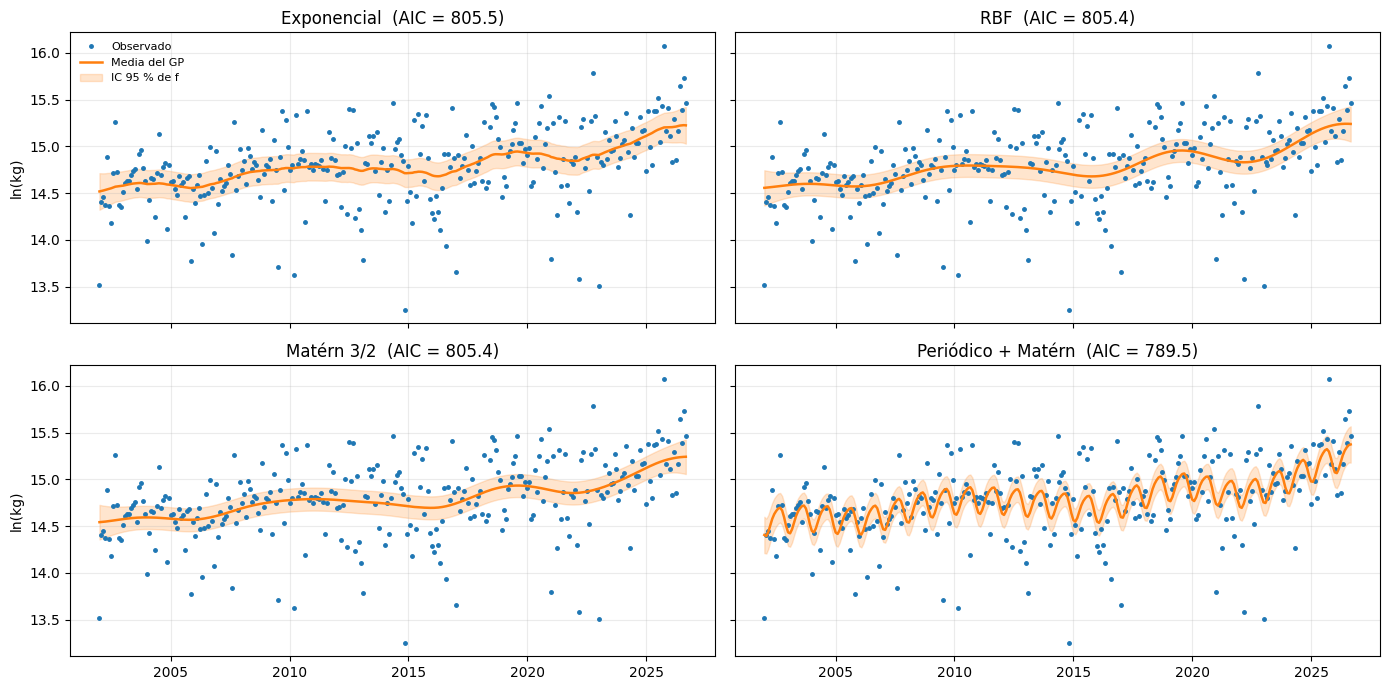

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex=True, sharey=True)
for ax, nombre in zip(axes.flat, list(modelos)[1:]):
    gp = modelos[nombre]
    mu, sd = gp.predict(X, return_std=True)
    sd_f = np.sqrt(np.clip(sd**2 - gp.kernel_.k2.noise_level, 0, None))
    ax.plot(t, b, '.', ms=5, color='tab:blue', label='Observado')
    ax.plot(t, nivel + escala * mu, color='tab:orange', lw=1.8, label='Media del GP')
    ax.fill_between(t, nivel + escala * (mu - 1.96 * sd_f), nivel + escala * (mu + 1.96 * sd_f),
                    color='tab:orange', alpha=.2, label='IC 95 % de f')
    ax.set_title(f'{nombre}  (AIC = {tabla_kernels.loc[nombre, "AIC"]:.1f})'); ax.grid(alpha=.25)
axes[0, 0].legend(frameon=False, fontsize=8)
for ax in axes[:, 0]: ax.set_ylabel('ln(kg)')
plt.tight_layout(); plt.show()

## 4. Descomposición de la varianza (objetivo 2)

Con el *Periódico + Matérn*, la varianza de cada componente (ciclo, tendencia y ruido) es su amplitud estimada. Se pasa a escala de ln(kg) multiplicando por el desvío al cuadrado.

In [17]:
gp_pm = modelos['Periódico + Matérn']
kp = gp_pm.kernel_
k_per, k_mat, k_ruido = kp.k1.k1, kp.k1.k2, kp.k2
var_comp = pd.Series({'Ciclo anual (periódico)': k_per.k1.constant_value,
                      'Tendencia (Matérn)': k_mat.k1.constant_value,
                      'Ruido blanco': k_ruido.noise_level})
desc = pd.DataFrame({'Varianza (estandarizada)': var_comp,
                     'Varianza (log)': var_comp * escala**2,
                     'Desvío (log)': np.sqrt(var_comp) * escala,
                     'Proporción': var_comp / var_comp.sum()})
display(desc.round(4))
print(f'Escala periódica ℓ = {k_per.k2.length_scale:.3f}; escala Matérn ℓ = {k_mat.k2.length_scale:.2f} años')
print(f'Un desvío del ciclo anual equivale a {100 * (np.exp(desc.loc["Ciclo anual (periódico)", "Desvío (log)"]) - 1):.0f} %')

,Varianza (estandarizada),Varianza (log),Desvío (log),Proporción
Ciclo anual (periódico),0.1602,0.0273,0.1651,0.1265
Tendencia (Matérn),0.3733,0.0635,0.2521,0.2948
Ruido blanco,0.7326,0.1247,0.3531,0.5787


Escala periódica ℓ = 1.538; escala Matérn ℓ = 4.65 años
Un desvío del ciclo anual equivale a 18 %


## 5. Diagnóstico de residuos

Con los residuos estandarizados, se calculan la ACF  y la PACF hasta 24 rezagos con la banda $\pm1{,}96/\sqrt{n}$, y se marcan como atípicos los meses que quedan fuera de la banda.

### Rezagos de la ACF y la PACF fuera de la banda, por modelo:

In [11]:
REZAGOS = 24
banda_fac = 1.96 / np.sqrt(n)
fuera = lambda r: [h for h in range(1, REZAGOS + 1) if abs(r[h]) > banda_fac]

filas, resid = [], {}
for nombre, gp in modelos.items():
    mu, sd = gp.predict(X, return_std=True)
    z = (y - mu) / sd
    resid[nombre] = (mu, sd, z)
    fac_fuera, facp_fuera = fuera(acf(z, nlags=REZAGOS)), fuera(pacf(z, nlags=REZAGOS, method='ywm'))
    filas.append((nombre, np.sqrt(np.mean((escala * (y - mu))**2)),
                  len(fac_fuera), str(fac_fuera), len(facp_fuera), str(facp_fuera),
                  np.mean(np.abs(z) > 1.96)))
diag = pd.DataFrame(filas, columns=['Modelo', 'RMSE ajuste (log)', 'ACF fuera', 'rezagos ACF',
                                    'PACF fuera', 'rezagos PACF', 'Fuera de banda 95 %']).set_index('Modelo')
print(f'Banda de la ACF y la PACF: ±{banda_fac:.3f} (rezagos 1 a {REZAGOS})')
display(diag.round(3))

Banda de la ACF y la PACF: ±0.114 (rezagos 1 a 24)


,RMSE ajuste (log),ACF fuera,rezagos ACF,PACF fuera,rezagos PACF,Fuera de banda 95 %
Modelo,,,,,,
Solo ruido,0.413,16,"[1, 2, 3, 5, 6, 8, 9, 10, 11, 12, 13, 14, 15, ...",6,"[1, 2, 3, 9, 10, 11]",0.061
Exponencial,0.360,4,"[4, 7, 20, 23]",3,"[4, 7, 20]",0.051
RBF,0.364,4,"[4, 7, 20, 23]",4,"[4, 7, 8, 20]",0.054
Matérn 3/2,0.364,4,"[4, 7, 20, 23]",3,"[4, 7, 20]",0.051
Periódico + Matérn,0.346,1,[7],1,[7],0.061


### Residuos, ACF y PACF: Matérn 3/2 vs. Periódico + Matérn


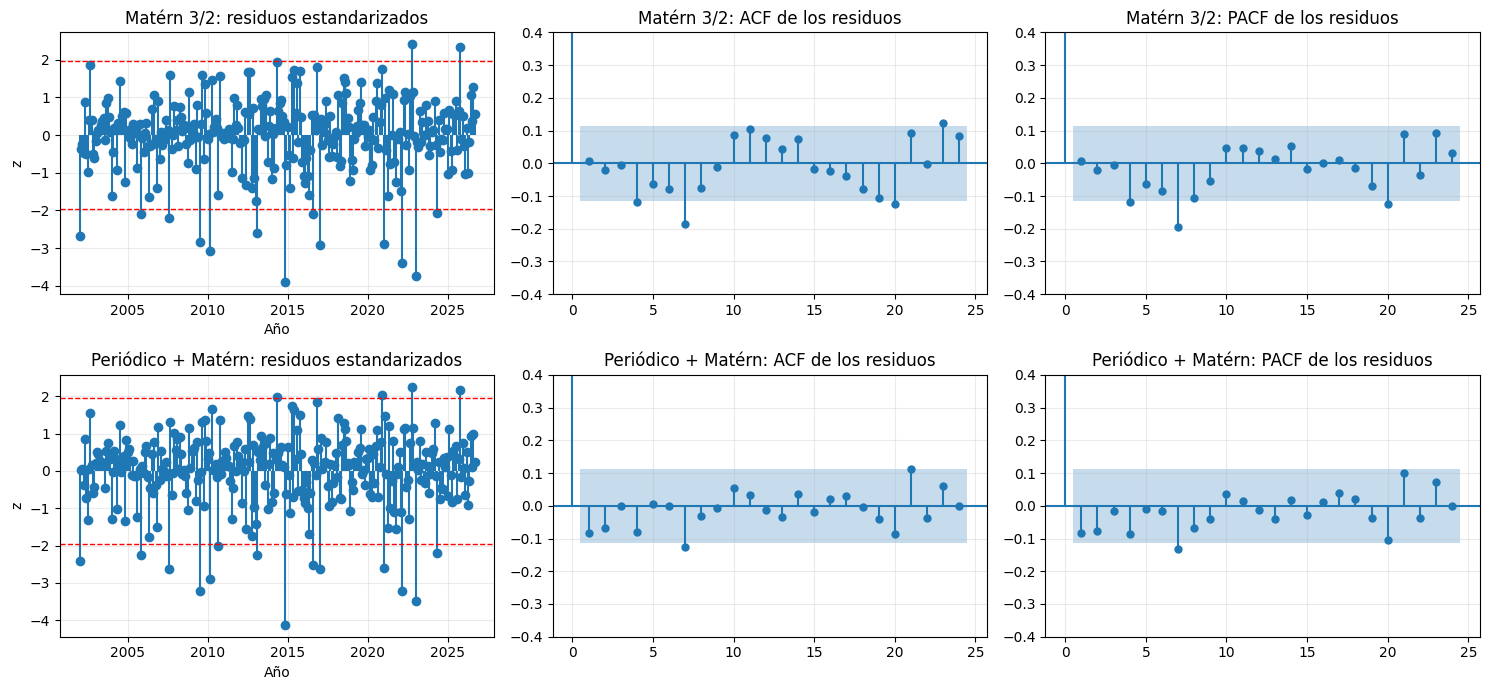

,mes,observado (M kg),ajustado (M kg),z
0,2002-01,0.74,1.80,-2.41
1,2005-11,0.96,2.16,-2.24
2,2007-08,1.02,2.62,-2.63
3,2009-07,0.90,2.86,-3.22
4,2010-03,0.83,2.34,-2.89
5,2010-09,1.46,3.01,-2.01
6,2013-02,0.97,2.19,-2.26
7,2014-05,5.19,2.55,1.97
8,2014-11,0.57,2.51,-4.12
9,2016-08,1.12,2.77,-2.51


In [12]:
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
for fila, nombre in enumerate(('Matérn 3/2', 'Periódico + Matérn')):
    z = resid[nombre][2]
    ax[fila, 0].stem(t, z, basefmt=' ')
    ax[fila, 0].axhline(1.96, color='r', ls='--', lw=1); ax[fila, 0].axhline(-1.96, color='r', ls='--', lw=1)
    ax[fila, 0].set(title=f'{nombre}: residuos estandarizados', xlabel='Año', ylabel='z')
    plot_acf(z, lags=REZAGOS, ax=ax[fila, 1], title=f'{nombre}: ACF de los residuos',
             bartlett_confint=False)
    plot_pacf(z, lags=REZAGOS, ax=ax[fila, 2], title=f'{nombre}: PACF de los residuos', method='ywm')
    for a in ax[fila, 1:]: a.set_ylim(-.4, .4)
for a in ax.flat: a.grid(alpha=.25)
plt.tight_layout(); plt.show()

mu_pm, sd_pm, z_pm = resid['Periódico + Matérn']
atip = np.where(np.abs(z_pm) > 1.96)[0]
display(pd.DataFrame({'mes': datos.index[atip].strftime('%Y-%m'),
                      'observado (M kg)': kg.values[atip] / 1e6,
                      'ajustado (M kg)': np.exp(nivel + escala * mu_pm[atip]) / 1e6,
                      'z': z_pm[atip]}).round(2))

## 6. Validación fuera de muestra (Objetivo 3)

Ventana expansiva, un origen cada 3 meses desde el mes 60 (79 orígenes) y horizonte de hasta 12 meses. En cada origen se reestiman los hiperparámetros. Se comparan tres GP (exponencial, Matérn 3/2 y Periódico + Matérn) con la media histórica, los naive y un ARIMA(1,0,0), mediante el RMSE y la cobertura de las bandas del 80 % y del 95 %.

### Pronósticos desde cada origen y tabla de RMSE y cobertura

In [13]:
H, PRIMER_ORIGEN, PASO = 12, 60, 3
ORIGENES = range(PRIMER_ORIGEN, n - 1, PASO)
z80, z95 = stats.norm.ppf(.9), stats.norm.ppf(.975)
GP_VALIDACION = ('Exponencial', 'Matérn 3/2', 'Periódico + Matérn')
registros = []

def registrar(modelo, o, obs, media, sd=None):
    for h, (yo, mu_h) in enumerate(zip(obs, media), start=1):
        s = np.nan if sd is None else sd[h - 1]
        c80 = float(abs(yo - mu_h) <= z80 * s) if sd is not None else np.nan
        c95 = float(abs(yo - mu_h) <= z95 * s) if sd is not None else np.nan
        registros.append((modelo, o, h, yo - mu_h, c80, c95))

for o in ORIGENES:
    te = np.arange(o, min(o + H, n))
    bb = b[:o]
    yy, nv, es = estandarizar(bb)
    cand = kernels_candidatos()
    for nombre in GP_VALIDACION:
        gp = ajustar(cand[nombre], X[:o], yy, reinicios=3)
        mu, sd = gp.predict(X[te], return_std=True)
        registrar('GP ' + nombre, o, b[te], nv + es * mu, es * sd)
    registrar('Media histórica', o, b[te], np.full(len(te), bb.mean()), np.full(len(te), bb.std(ddof=1)))
    registrar('Naive', o, b[te], np.full(len(te), bb[-1]))
    registrar('Naive estacional', o, b[te], np.array([b[j - 12 * ((j - o) // 12 + 1)] for j in te]))
    ar = ARIMA(bb, order=(1, 0, 0), trend='c').fit()
    f = ar.get_forecast(len(te))
    registrar('ARIMA(1,0,0)', o, b[te], f.predicted_mean, np.sqrt(f.var_pred_mean))

R = pd.DataFrame(registros, columns=['modelo', 'origen', 'h', 'error', 'cub80', 'cub95'])
R['tramo'] = pd.cut(R['h'], [0, 1, 3, 6, 12], labels=['h=1', 'h=2-3', 'h=4-6', 'h=7-12'])
rmse = lambda e: np.sqrt(np.mean(e**2))
tabla_rmse = R.pivot_table(index='modelo', columns='tramo', values='error', aggfunc=rmse, observed=True)
tabla_rmse['Total'] = R.groupby('modelo')['error'].apply(rmse)
tabla_rmse['Cobertura 80 %'] = R.groupby('modelo')['cub80'].mean()
tabla_rmse['Cobertura 95 %'] = R.groupby('modelo')['cub95'].mean()
print(f'Orígenes: {R.origen.nunique()}; pronósticos por modelo: {len(R) // R.modelo.nunique()}')
display(tabla_rmse.sort_values('Total').round(3))

Orígenes: 79; pronósticos por modelo: 930


tramo,h=1,h=2-3,h=4-6,h=7-12,Total,Cobertura 80 %,Cobertura 95 %
modelo,,,,,,,
GP Periódico + Matérn,0.416,0.385,0.400,0.407,0.402,0.770,0.912
GP Exponencial,0.435,0.394,0.412,0.414,0.412,0.755,0.912
GP Matérn 3/2,0.435,0.394,0.412,0.414,0.412,0.752,0.911
"ARIMA(1,0,0)",0.440,0.431,0.441,0.444,0.441,0.714,0.887
Media histórica,0.449,0.432,0.441,0.444,0.442,0.715,0.887
Naive,0.577,0.489,0.537,0.501,0.515,NaN,NaN
Naive estacional,0.568,0.505,0.530,0.532,0.530,NaN,NaN


## 7. Sensibilidad a las cotas y a los reinicios

Se reajusta el *Periódico + Matérn* cambiando una cota por vez, con 5 semillas y 5 reinicios cada una. La última variante deja libre el período entre 0,95 y 1,05.

In [14]:
variantes = {
    'Base (período = 1, ℓ ≥ 1/12)': dict(),
    'ℓ Matérn ≥ 0,02': dict(l_min=.02),
    'ℓ periódico ≥ 0,3': dict(l_per_min=.3),
    'Período libre [0,95; 1,05]': dict(periodo_libre=True),
}
SEMILLAS = range(5)

def ajustar_semillas(kw, XX, yy):
    '''Ajusta con varias semillas y devuelve el mejor ajuste y los óptimos distintos encontrados.'''
    ajustes = [ajustar(kernels_candidatos(**kw)['Periódico + Matérn'], XX, yy, reinicios=5, semilla=s) for s in SEMILLAS]
    mejor = max(ajustes, key=lambda g: g.log_marginal_likelihood_value_)
    optimos = sorted({(round(float(g.log_marginal_likelihood_value_), 2), round(float(g.kernel_.k1.k1.k2.periodicity), 3),
                       round(float(g.kernel_.k1.k1.k2.length_scale), 3)) for g in ajustes}, reverse=True)
    return mejor, optimos

filas, optimos_var = [], {}
for nombre, kw in variantes.items():
    gp, optimos_var[nombre] = ajustar_semillas(kw, X, y)
    kk = gp.kernel_
    lml = gp.log_marginal_likelihood_value_
    filas.append((nombre, lml, 2 * kk.n_dims - 2 * lml, kk.k1.k1.k2.periodicity, kk.k1.k1.k2.length_scale,
                  kk.k1.k1.k1.constant_value, kk.k1.k2.k2.length_scale, kk.k2.noise_level, len(optimos_var[nombre])))
sens = pd.DataFrame(filas, columns=['Variante', 'logML', 'AIC', 'período', 'ℓ per', 'σ² per', 'ℓ Matérn',
                                    'σ² ruido', 'óptimos distintos']).set_index('Variante')
display(sens.round(3))

print('Óptimos locales (logML, período, ℓ periódico) encontrados con 5 semillas × 5 reinicios:')
for v in ('Base (período = 1, ℓ ≥ 1/12)', 'Período libre [0,95; 1,05]'):
    print(f'  {v}: {optimos_var[v]}')

,logML,AIC,período,ℓ per,σ² per,ℓ Matérn,σ² ruido,óptimos distintos
Variante,,,,,,,,
"Base (período = 1, ℓ ≥ 1/12)",-389.729,789.458,1.000,1.538,0.160,4.652,0.733,1
"ℓ Matérn ≥ 0,02",-389.729,789.458,1.000,1.538,0.160,4.652,0.733,1
"ℓ periódico ≥ 0,3",-389.729,789.458,1.000,1.538,0.160,4.652,0.733,1
"Período libre [0,95; 1,05]",-389.391,790.782,1.003,1.426,0.154,4.631,0.730,2


Óptimos locales (logML, período, ℓ periódico) encontrados con 5 semillas × 5 reinicios:
  Base (período = 1, ℓ ≥ 1/12): [(-389.73, 1.0, 1.538)]
  Período libre [0,95; 1,05]: [(-389.39, 1.003, 1.426), (-389.39, 1.003, 1.421)]


## 8. Pronóstico oct-2026 a sep-2027

Ajuste del *Periódico + Matérn* con toda la serie y pronóstico de 12 meses. $e^{\hat b}$ estima la mediana en kg.

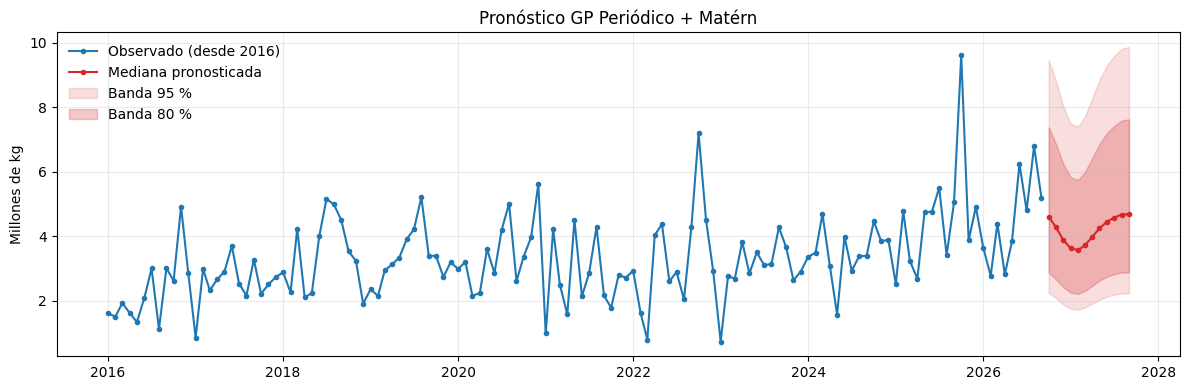

mes,2026-10,2026-11,2026-12,2027-01,2027-02,2027-03,2027-04,2027-05,2027-06,2027-07,2027-08,2027-09
mediana (M kg),4.60,4.27,3.88,3.62,3.57,3.71,3.98,4.24,4.44,4.58,4.67,4.68
inf 95 %,2.24,2.07,1.88,1.75,1.72,1.79,1.91,2.03,2.12,2.18,2.22,2.22
sup 95 %,9.47,8.80,8.02,7.49,7.39,7.72,8.28,8.85,9.29,9.59,9.81,9.87


In [15]:
fechas_f = pd.date_range(datos.index[-1] + pd.offsets.MonthBegin(), periods=12, freq='MS')
t_f = (fechas_f.year + (fechas_f.month - 1) / 12).values.astype(float)
mu_f, sd_f = gp_pm.predict((t_f - t0).reshape(-1, 1), return_std=True)
med = np.exp(nivel + escala * mu_f)
lo80, hi80 = np.exp(nivel + escala * (mu_f - z80 * sd_f)), np.exp(nivel + escala * (mu_f + z80 * sd_f))
lo95, hi95 = np.exp(nivel + escala * (mu_f - z95 * sd_f)), np.exp(nivel + escala * (mu_f + z95 * sd_f))

fig, ax = plt.subplots(figsize=(12, 4))
desde = datos.index >= '2016-01-01'
ax.plot(datos.index[desde], kg[desde] / 1e6, 'o-', ms=3, label='Observado (desde 2016)')
ax.plot(fechas_f, med / 1e6, 'o-', color='tab:red', ms=3, label='Mediana pronosticada')
ax.fill_between(fechas_f, lo95 / 1e6, hi95 / 1e6, color='tab:red', alpha=.15, label='Banda 95 %')
ax.fill_between(fechas_f, lo80 / 1e6, hi80 / 1e6, color='tab:red', alpha=.25, label='Banda 80 %')
ax.set(ylabel='Millones de kg', title='Pronóstico GP Periódico + Matérn'); ax.legend(frameon=False); ax.grid(alpha=.25)
plt.tight_layout(); plt.show()

display(pd.DataFrame({'mes': fechas_f.strftime('%Y-%m'), 'mediana (M kg)': med / 1e6,
                      'inf 95 %': lo95 / 1e6, 'sup 95 %': hi95 / 1e6}).round(2).set_index('mes').T)

## 9. Síntesis de resultados

In [16]:
GP = 'GP Periódico + Matérn'
aic = tabla_kernels['AIC'].sort_values()
rmse = tabla_rmse['Total'].sort_values()
mejora = 1 - rmse[GP] / rmse.drop(GP).min()
verbo = 'reduce' if mejora > 0 else 'aumenta'

print(f'1. Estructura: mejor AIC = {aic.index[0]} (ΔAIC vs. 2.º = {aic.iloc[1]-aic.iloc[0]:.1f}); '
      f'ciclo anual: ΔlogML = {d:.2f}.')
print('2. Magnitud (varianza): ' + ', '.join(f'{i} {v:.0%}' for i, v in desc['Proporción'].items()) + '.')
print(f'3. Utilidad: RMSE de {GP} = {rmse[GP]:.3f} '
      f'({verbo} el RMSE un {abs(mejora):.1%} vs. mejor baseline); '
      f'cobertura 95 %: {tabla_rmse.loc[GP, "Cobertura 95 %"]:.1%}, '
      f'80 %: {tabla_rmse.loc[GP, "Cobertura 80 %"]:.1%}.')

1. Estructura: mejor AIC = Periódico + Matérn (ΔAIC vs. 2.º = 15.9); ciclo anual: ΔlogML = 9.95.
2. Magnitud (varianza): Ciclo anual (periódico) 13%, Tendencia (Matérn) 29%, Ruido blanco 58%.
3. Utilidad: RMSE de GP Periódico + Matérn = 0.402 (reduce el RMSE un 2.3% vs. mejor baseline); cobertura 95 %: 91.2%, 80 %: 77.0%.
